<a href="https://colab.research.google.com/github/anna-pauliina-p/Datheon_Machine_Learning_-_Data_Science_Internship/blob/main/Task3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
from imblearn.over_sampling import SMOTE

# 1. Load the Telco Customer Churn dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# Display first few rows to verify
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:


# Drop customerID as it's a unique identifier, not a feature
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

# Convert TotalCharges to numeric (some missing/blank values might be stored as strings)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Impute missing values in TotalCharges with median
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# Convert Target variable (Churn) from 'Yes'/'No' to 1/0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Separate features (X) and target variable (y)
X = df.drop(columns=['Churn'])
y = df['Churn']

# 1. SPLIT INTO TRAINING AND TEST SETS FIRST (80% / 20%)
# This ensures zero data leakage from the test set into our scaler or encoder
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Identify categorical and numerical columns from X_train
categorical_cols = X_train_raw.select_dtypes(include=['object', 'category']).columns
numerical_cols = X_train_raw.select_dtypes(include=[np.number]).columns

# Preprocessing pipeline for numerical and categorical data
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
    ]
)

# 2. FIT ONLY ON THE TRAINING DATA, then transform both train and test sets
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("Training feature matrix shape:", X_train.shape)
print("Testing feature matrix shape:", X_test.shape)
print("Target array shape:", y_train.shape, y_test.shape)

# 3. Preview processed training features as a Pandas DataFrame
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_cols = cat_encoder.get_feature_names_out(categorical_cols).tolist()
all_feature_names = list(numerical_cols) + encoded_cat_cols

df_processed_preview = pd.DataFrame(X_train, columns=all_feature_names)
display(df_processed_preview.head())

print("Any NaN values remaining in processed training features?", np.isnan(X_train).any())
print("Any NaN values remaining in processed testing features?", np.isnan(X_test).any())

Training feature matrix shape: (5634, 30)
Testing feature matrix shape: (1409, 30)
Target array shape: (5634,) (1409,)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,-0.441773,0.102371,-0.521976,-0.263289,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.441773,-0.711743,0.337478,-0.504814,1.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-0.441773,-0.793155,-0.809013,-0.751213,1.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,-0.441773,-0.263980,0.284384,-0.173699,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0
4,-0.441773,-1.281624,-0.676279,-0.990851,1.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


Any NaN values remaining in processed training features? False
Any NaN values remaining in processed testing features? False


In [ ]:
# 3. Balance target classes using SMOTE on the training set
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f"Before SMOTE - Training shape: {X_train.shape}, Churn counts: {np.bincount(y_train)}")
print(f"After SMOTE  - Training shape: {X_train_smote.shape}, Churn counts: {np.bincount(y_train_smote)}")

Before SMOTE - Training shape: (5634, 30), Churn counts: [4139 1495]
After SMOTE  - Training shape: (8278, 30), Churn counts: [4139 4139]



--- Random Forest Performance ---
ROC-AUC Score: 0.8238
Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1035
           1       0.58      0.58      0.58       374

    accuracy                           0.78      1409
   macro avg       0.71      0.71      0.71      1409
weighted avg       0.78      0.78      0.78      1409



/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [08:30:18] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



--- XGBoost Performance ---
ROC-AUC Score: 0.8243
Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.86      0.85      1035
           1       0.60      0.59      0.60       374

    accuracy                           0.79      1409
   macro avg       0.73      0.72      0.72      1409
weighted avg       0.79      0.79      0.79      1409



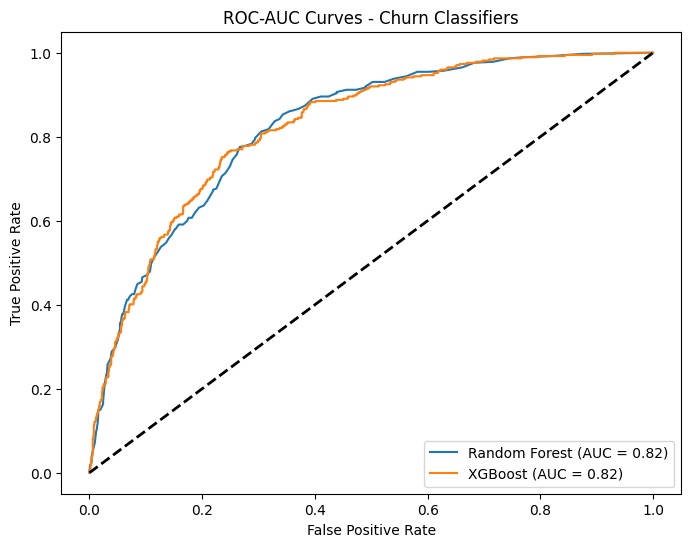

In [ ]:
# 4. Train Models (Random Forest & XGBoost)
models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}

trained_models = {}
plt.figure(figsize=(8, 6))

for name, model in models.items():
    # Train model on SMOTE-balanced data
    model.fit(X_train_smote, y_train_smote)
    trained_models[name] = model

    # Predict probabilities for ROC-AUC
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    auc_score = roc_auc_score(y_test, y_pred_proba)

    print(f"\n--- {name} Performance ---")
    print(f"ROC-AUC Score: {auc_score:.4f}")

    # Classification Report & Confusion Matrix
    y_pred = model.predict(X_test)
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    # Plot ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.2f})")

# Finalize ROC Plot
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curves - Churn Classifiers')
plt.legend(loc='lower right')
plt.show()

/tmp/ipykernel_2993/2825519635.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=top_10_features, palette='viridis')


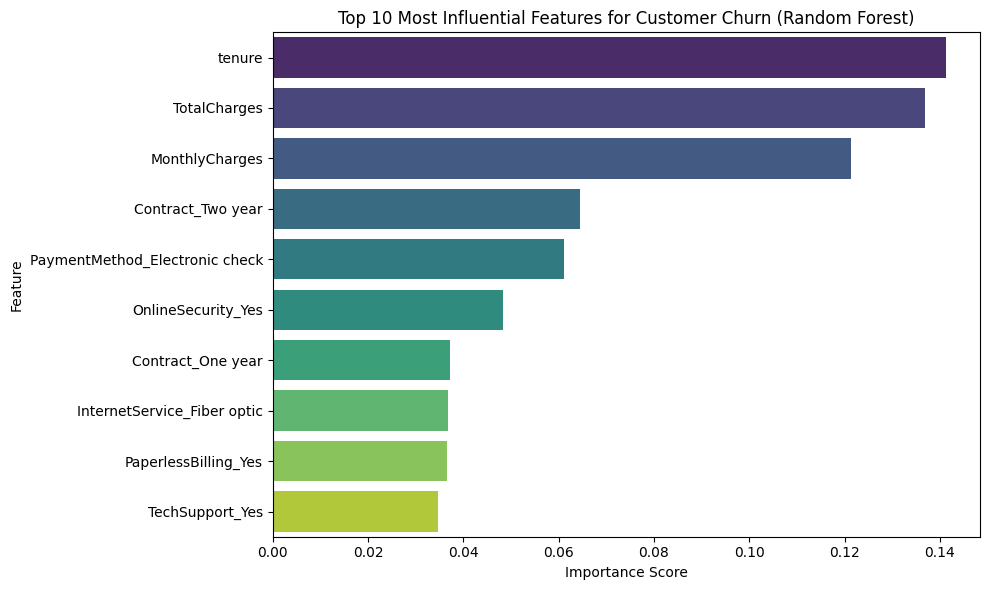

In [ ]:
# 5. Extract and Plot Top 10 Feature Importances (Using Random Forest)
# Retrieve feature names after OneHotEncoding
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_cols = cat_encoder.get_feature_names_out(categorical_cols).tolist()
all_feature_names = list(numerical_cols) + encoded_cat_cols

rf_importances = trained_models["Random Forest"].feature_importances_
feature_imp_df = pd.DataFrame({'Feature': all_feature_names, 'Importance': rf_importances})
top_10_features = feature_imp_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=top_10_features, palette='viridis')
plt.title('Top 10 Most Influential Features for Customer Churn (Random Forest)')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()